# **Notebook 1: Data Understanding & Exploratory Data Analysis**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED for this notebook:**
- [ ] `corporate_policies/` folder with `.md` SOP files uploaded to Colab:
  - `refund_policy.md`, `shipping_delays.md`, `password_reset.md`, `technical_troubleshooting.md`, `escalation_matrix.md`
- [ ] Internet access (to download Bitext dataset from HuggingFace)

**Files this notebook will CREATE:**
- [ ] `sampled_data.csv` — Cleaned, deduplicated, 4000-row sample of the Bitext dataset
  _(Required by: Notebook 2 — Data Preparation)_

> **Note:** Tasks 1.1 (Define Project Scope) and 1.4 (Design Methodology) are documented in your **Project Proposal PDF**, not this notebook. This notebook covers Tasks **1.2** and **1.3**.

---

## **Stage 1: Data Understanding & EDA**
### **Task 1.2: Understand and Assess Data**

#### **1.2.1 Inspect Dataset Structure [2 marks]**
**The Task:** Identify the presence of the corporate policy files within the local environment and successfully download the `bitext` customer support dataset from Hugging Face. Print the dataset information.

**Hints & Tips:**
* Use `glob` to find `.md` files in your workspace, and `load_dataset` for the bitext data.
* The dataset ID is `bitext/Bitext-customer-support-llm-chatbot-training-dataset` — it contains ~26,872 rows.
* Key columns: `instruction` (user query), `intent` (target class), `category` (broader group).

**Why we are doing it:** To ensure the local environment is properly configured with our knowledge base before reading data.
**How we are doing it:** Check the `corporate_policies` directory, load the dataset, and use `.info()`.

**Learner Inference:** If the files load correctly, your environment is stable. Seeing the 'intent' column confirms the target variable you will train your model to extract in Stage 4.

In [2]:
# YOUR CODE HERE
import os, glob, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

SEED = 42
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"   # use the same value in ALL notebooks

# Find the SOP markdown files
SOP_DIR = "data/Dataset/sop_documents"
sop_files = sorted(glob.glob(os.path.join(SOP_DIR, "*.md")))
print(f"Found {len(sop_files)} SOP files in {SOP_DIR}")
for f in sop_files:
    print("  -", os.path.basename(f))

# Load the Bitext customer support dataset
ds = load_dataset("bitext/Bitext-customer-support-llm-chatbot-training-dataset")
df_full = ds["train"].to_pandas()
print()
df_full.info()

Found 13 SOP files in data/Dataset/sop_documents
  - account_recovery.md
  - billing_disputes.md
  - data_privacy.md
  - escalation_matrix.md
  - order_tracking.md
  - password_reset.md
  - payment_methods.md
  - product_return.md
  - refund_policy.md
  - shipping_delays.md
  - subscription_cancellation.md
  - technical_troubleshooting.md
  - working_hours.md



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26872 entries, 0 to 26871
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   flags        26872 non-null  object
 1   instruction  26872 non-null  object
 2   category     26872 non-null  object
 3   intent       26872 non-null  object
 4   response     26872 non-null  object
dtypes: object(5)
memory usage: 1.0+ MB


#### **1.2.2 Quantify Dataset Characteristics [3 marks]**
**The Task:** Calculate the original size of the dataset, identify the number of unique intents, and randomly sample the dataset down to 4,000 rows.

**Hints & Tips:**
* Use `len()`, `.nunique()`, and `.sample(4000, random_state=42)`.
* `random_state=42` ensures reproducibility — everyone gets the same sample.
* With 4000 rows and 27 intents, you'll get ~148 examples per intent on average.

**Parameter Tuning:**
* `sample(n)` — try 1000–5000 per the workflow spec:
  - `1000`: Fast (~1 min), lower accuracy
  - `4000`: Moderate (~3 min), better accuracy (recommended)
  - `5000`: Slower, best accuracy, may hit T4 memory limits

**Learner Inference:** Capping at 4000 rows keeps your Stage 4 training loop to minutes while providing enough examples per intent.

In [3]:
print("Dataset size:", len(df_full))
print("Number of intents:", df_full["intent"].nunique())
print("Number of categories:", df_full["category"].nunique())

# Take a random sample of 4000 records
df = df_full.sample(n=4000, random_state=42).reset_index(drop=True)

print("\nSample size:", len(df))
print("Average records per intent:", round(len(df) / df["intent"].nunique()))

# Check the length of customer queries
df["n_words"] = df["instruction"].str.split().str.len()

df["n_words"].describe().round(1)

Dataset size: 26872
Number of intents: 27
Number of categories: 11

Sample size: 4000
Average records per intent: 148


count    4000.0
mean        8.8
std         2.6
min         1.0
25%         7.0
50%         9.0
75%        11.0
max        16.0
Name: n_words, dtype: float64

count    4000.0
mean       10.2
std         3.1
min         1.0
25%         8.0
50%        10.0
75%        12.0
max        21.0
Name: n_tokens, dtype: float64
Longest query: 21 tokens


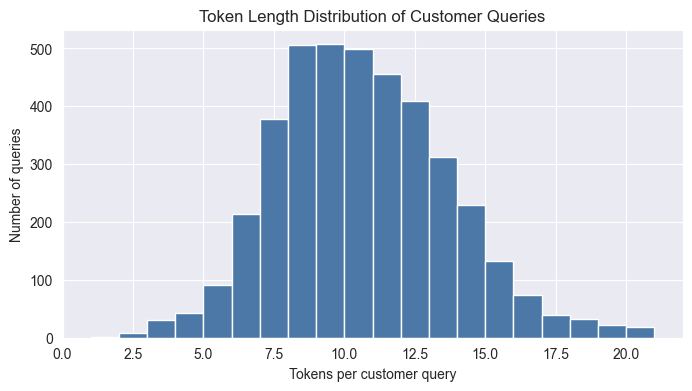

In [4]:
# Token length of each customer query (counted with the same Qwen tokenizer
# used later in the project).
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

df["n_tokens"] = df["instruction"].apply(lambda t: len(tokenizer(t)["input_ids"]))

print(df["n_tokens"].describe().round(1))
print("Longest query:", df["n_tokens"].max(), "tokens")

# histogram of query lengths in tokens
plt.figure(figsize=(8, 4))
plt.hist(df["n_tokens"], bins=20, color="#4C78A8")
plt.xlabel("Tokens per customer query")
plt.ylabel("Number of queries")
plt.title("Token Length Distribution of Customer Queries")
plt.show()

##### 1.2.2 Token Length Conclusion

Customer queries were tokenised with the Qwen tokenizer to measure their length in tokens, not just words.

- **Average:** 10.2 tokens (std 3.1), median 10.
- **Range:** 1 to 21 tokens. 75% of queries have 12 tokens or fewer.
- **Shape:** the histogram is roughly bell-shaped, with most queries between 8 and 12 tokens and a short tail up to 21.

The queries are very short, so truncation is not a risk. After the chat template and the JSON answer are added in Notebook 2, a full training record is about 55 tokens, well below the 128-token limit chosen for fine-tuning.

#### **1.2.3 Validate Sample Quality [2 marks]**
**The Task:** Identify and remove records containing null values or duplicated customer instructions using normalised deduplication.

**Hints & Tips:**
* Use `.isnull().sum()` to check nulls.
* Simple `drop_duplicates` misses near-dupes like `"Where is my order?"` vs `"where is my order?"`.
* Normalise to lowercase + strip whitespace BEFORE deduplicating to catch these.
* The Bitext dataset typically has ~15 near-duplicates in a 4000-row sample.

**Learner Inference:** Cleaning now prevents "garbage-in, garbage-out". Duplicate prompts can cause leakage between train and test sets later.

In [3]:
# YOUR CODE HERE
# check for missing values
print(df[["instruction", "intent", "category"]].isnull().sum())

# remove rows with missing values or empty text
df = df.dropna(subset=["instruction", "intent", "category"])
df = df[df["instruction"].str.strip() != ""]

# make a temporary lowercase column so "Hello" and "hello " count as the same
df["temp"] = df["instruction"].str.lower().str.strip()

print("Rows before removing duplicates:", len(df))
print("Normal duplicates:", df.duplicated(subset=["instruction"]).sum())
print("Duplicates after lowercase and strip:", df.duplicated(subset=["temp"]).sum())

# remove the duplicates and drop the temporary column
df = df.drop_duplicates(subset=["temp"])
df = df.drop(columns=["temp"])
df = df.reset_index(drop=True)

print("Rows after removing duplicates:", len(df))

# each intent should belong to only one category
check = df.groupby("intent")["category"].nunique()
print("Intents with more than one category:", (check > 1).sum())

# the assignment needs between 1000 and 5000 rows
print("Rows within 1000 to 5000:", 1000 <= len(df) <= 5000)

instruction    0
intent         0
category       0
dtype: int64
Rows before removing duplicates: 4000
Normal duplicates: 83
Duplicates after lowercase and strip: 98
Rows after removing duplicates: 3902
Intents with more than one category: 0
Rows within 1000 to 5000: True


### **Task 1.3: Perform Exploratory Data Analysis**

#### **1.3.1 Perform Univariate Analysis [2 marks]**
**The Task:** Plot the top 10 most frequent customer intents using a horizontal bar chart.

**Hints & Tips:**
* Use a Seaborn `countplot` with `order=df['intent'].value_counts().index[:10]`.
* Check if any single intent dominates >80% of data — signals severe class imbalance.
* `palette="viridis"` works well for accessibility.

**Learner Inference:** This visual reveals class imbalance. If one intent dominates, your fine-tuned router becomes biased toward guessing it.

C:\Users\divya\AppData\Local\Temp\ipykernel_56140\827762946.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y="intent", order=top10, palette="viridis")


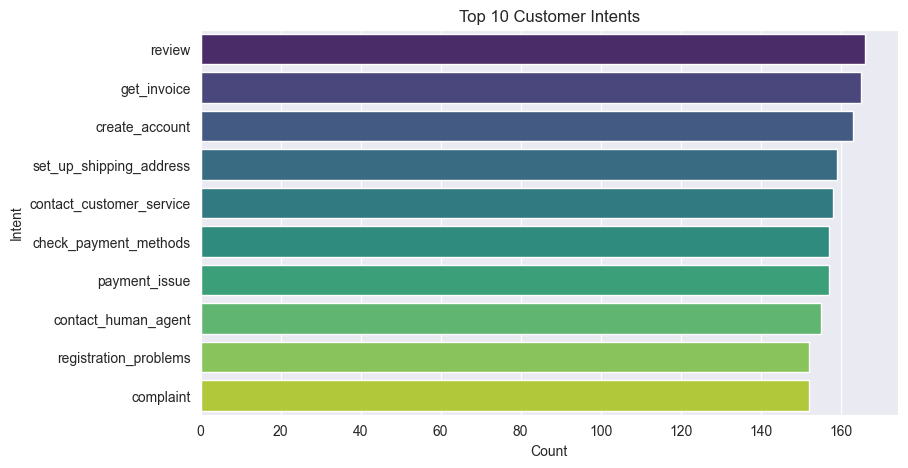

Most common intent: review - 166 rows
Least common intent: cancel_order - 108 rows
Share of most common intent: 4.3 %
Is one intent above 80%? False


In [4]:
# YOUR CODE HERE
# find the 10 most common intents
top10 = df["intent"].value_counts().index[:10]

# draw a horizontal bar chart
plt.figure(figsize=(9, 5))
sns.countplot(data=df, y="intent", order=top10, palette="viridis")
plt.title("Top 10 Customer Intents")
plt.xlabel("Count")
plt.ylabel("Intent")
plt.show()

# check if one intent has too much data (class imbalance)
counts = df["intent"].value_counts()
print("Most common intent:", counts.index[0], "-", counts.iloc[0], "rows")
print("Least common intent:", counts.index[-1], "-", counts.iloc[-1], "rows")
print("Share of most common intent:", round(counts.iloc[0] / len(df) * 100, 1), "%")
print("Is one intent above 80%?", counts.iloc[0] / len(df) > 0.8)

#### **1.3.2 Perform Bivariate Analysis [2 marks]**
**The Task:** Read the text from the uploaded Markdown SOP files and fit a `TfidfVectorizer` (with `stop_words='english'`) to transform them into vectors.

**Hints & Tips:**
* Read files into a list of strings first using `open(f, 'r').read()`.
* `TfidfVectorizer(stop_words="english")` removes common words, keeping meaningful terms.
* The resulting matrix shape should be `(num_docs, num_unique_terms)`.

**Learner Inference:** This transforms raw text into math, letting you prove whether your policies are distinct enough for an AI to tell apart.

In [5]:
# YOUR CODE HERE
from sklearn.feature_extraction.text import TfidfVectorizer

# read every SOP file into a list
sop_names = []
sop_texts = []
for file in sop_files:
    with open(file, "r", encoding="utf-8") as f:
        sop_texts.append(f.read())
    sop_names.append(os.path.basename(file).replace(".md", ""))

print("Number of SOP documents:", len(sop_texts))

# convert the text into numbers (TF-IDF), ignoring common english words
tfidf = TfidfVectorizer(stop_words="english")
sop_matrix = tfidf.fit_transform(sop_texts)

print("Matrix shape (documents, unique words):", sop_matrix.shape)
print("First 15 words:", list(tfidf.get_feature_names_out()[:15]))

Number of SOP documents: 13
Matrix shape (documents, unique words): (13, 797)
First 15 words: ['00', '08', '10', '12', '18', '20', '21', '24', '30', '48', '60', 'acceptable', 'accepted', 'accepts', 'access']


#### **1.3.3 Generate Visualisations [2 marks]**
**The Task:** Calculate cosine similarity between the TF-IDF vectors of the SOP documents and plot an annotated heatmap.

**Hints & Tips:**
* Use `cosine_similarity` from sklearn and `sns.heatmap` with `annot=True`.
* Diagonal should always be 1.0 (document vs itself).
* Off-diagonal >0.5 = high overlap (RAG may struggle); <0.3 = low overlap (good retrieval).

**Learner Inference:** High overlap (dark off-diagonal squares) means the RAG system struggles to fetch the right doc. Low overlap proves retrieval will be accurate.

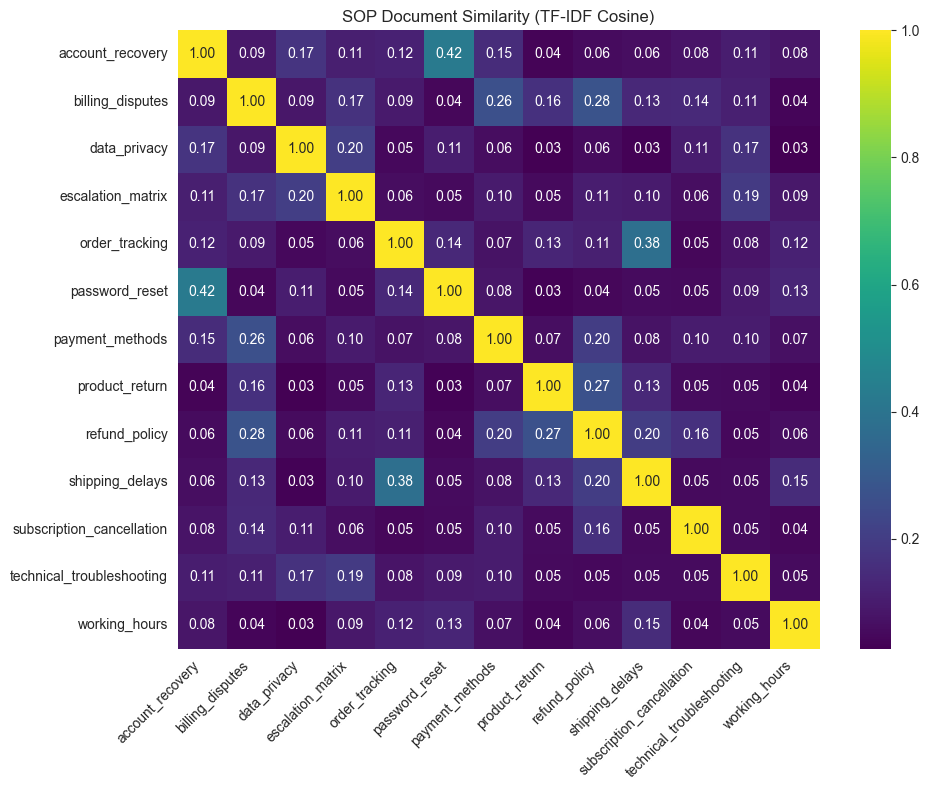

Top 5 most similar SOP pairs:
account_recovery <-> password_reset : 0.424
order_tracking <-> shipping_delays : 0.379
billing_disputes <-> refund_policy : 0.278
product_return <-> refund_policy : 0.269
billing_disputes <-> payment_methods : 0.264
Pairs with similarity above 0.5: 0


In [6]:
# YOUR CODE HERE
from sklearn.metrics.pairwise import cosine_similarity

# compare every SOP with every other SOP
similarity = cosine_similarity(sop_matrix)

# draw the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(similarity, annot=True, fmt=".2f", cmap="viridis",
            xticklabels=sop_names, yticklabels=sop_names)
plt.title("SOP Document Similarity (TF-IDF Cosine)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# list the most similar pairs of documents
pairs = []
for i in range(len(sop_names)):
    for j in range(i + 1, len(sop_names)):
        pairs.append((sop_names[i], sop_names[j], similarity[i][j]))

pairs.sort(key=lambda x: x[2], reverse=True)

print("Top 5 most similar SOP pairs:")
for a, b, score in pairs[:5]:
    print(a, "<->", b, ":", round(score, 3))

print("Pairs with similarity above 0.5:", sum(1 for p in pairs if p[2] > 0.5))


---
## Save Artifacts for Notebook 2

**IMPORTANT:** This cell saves the cleaned DataFrame. Notebook 2 depends on this file.

In [7]:
# YOUR CODE HERE
# keep only the 3 columns we need and save the cleaned data
df_final = df[["instruction", "intent", "category"]]
df_final.to_csv("sampled_data.csv", index=False)

print("Saved sampled_data.csv")
print("Rows and columns:", df_final.shape)
print("Unique intents:", df_final["intent"].nunique())

Saved sampled_data.csv
Rows and columns: (3902, 3)
Unique intents: 27



# 1. Business Objective and Data Understanding

## 1.1 Business Objective

The aim of this project is to build a customer support system that can understand customer queries, identify the relevant intent and category, and use company policy documents to provide more reliable responses.

The project combines an LLM with Retrieval-Augmented Generation (RAG) and fine-tuning to improve how customer queries are handled. Instead of relying only on the model's existing knowledge, the system will use customer support data to identify the query type and retrieve relevant information from the company's policies.

The main objectives are:
- Identify customer support intents.
- Assign the appropriate category to customer queries.
- Retrieve relevant information from company policy documents.
- Generate responses based on the retrieved policy information.
- Compare the performance of a baseline model, RAG and a fine-tuned RAG solution.

## 1.2 Data Understanding

The project uses the Bitext Customer Support dataset and a collection of corporate SOP documents.

The customer support dataset contains customer queries along with their associated intent, category and response information. These records will be used to prepare the data for intent classification and model training.

The SOP documents contain information about company policies and customer support procedures. These documents will be used as the knowledge base for retrieval during response generation.

The policy documents cover topics such as account recovery, password reset, refunds, product returns, shipping delays, order tracking, billing disputes, payment methods, technical troubleshooting, data privacy, subscription cancellation, escalation procedures and working hours.

The customer support dataset will be used to train and evaluate the model, while the SOP documents will provide the information needed to generate policy-related responses.

## 1.3 Exploratory Data Analysis

### 1.3.1 Univariate Analysis – Customer Intent Distribution

A horizontal bar chart was created to visualize the top 10 customer support intents in the dataset.

The top 10 intents were:

- review
- get_invoice
- create_account
- set_up_shipping_address
- contact_customer_service
- check_payment_methods
- payment_issue
- contact_human_agent
- registration_problems
- complaint

The most frequent intent was `review`, with 166 records. The least frequent intent in the overall dataset was `cancel_order`, with 108 records.

The most frequent intent accounted for approximately 4.3% of the dataset. No single intent accounted for more than 80% of the records.

The distribution does not show extreme imbalance, as no single intent dominates the dataset. This is useful for training an intent classification model, although the distribution of individual intents will still need to be considered when splitting the data for training and evaluation.

### 1.3.2 Bivariate Analysis – TF-IDF Vectorization of SOP Documents

The text from the 13 SOP documents was converted into numerical vectors using `TfidfVectorizer`, with English stop words removed.

The vectorization produced the following results:

- SOP documents: 13
- Unique vocabulary terms: 797
- TF-IDF matrix shape: (13, 797)

TF-IDF assigns weights to words based on their importance within a document and across the document collection. This allows the SOP documents to be represented numerically and compared with each other.

### 1.3.3 Visualization – SOP Document Similarity

Cosine similarity was calculated between the TF-IDF vectors of the 13 SOP documents. The results were displayed using an annotated heatmap.

The five most similar document pairs were:

| SOP document pair | Similarity |
|---|---:|
| account_recovery and password_reset | 0.424 |
| order_tracking and shipping_delays | 0.379 |
| billing_disputes and refund_policy | 0.278 |
| product_return and refund_policy | 0.269 |
| billing_disputes and payment_methods | 0.264 |

The diagonal values in the heatmap were 1.00, as each document was compared with itself. No document pair had a similarity score above 0.5.

The highest similarity was found between `account_recovery` and `password_reset`, followed by `order_tracking` and `shipping_delays`. These documents cover related topics, so some overlap in their vocabulary is expected.

None of the document pairs had a similarity score above 0.5. This suggests that the documents have distinguishable text content based on the TF-IDF representation. However, this does not guarantee retrieval accuracy, which will need to be tested during the RAG implementation.

## 1.4 Saving the Cleaned Dataset

The cleaned dataset was saved as `sampled_data.csv` for use in the subsequent data preparation stage.

The final dataset contains the following columns:

- `instruction` – customer query
- `intent` – customer support intent
- `category` – broader customer support category

The saved dataset contains 3,902 records, 3 columns and 27 unique intents.

The cleaned dataset will be used in the next stage for further data preparation, splitting and model training.


---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify all items before proceeding to Notebook 2.**

- [ ] Bitext dataset loaded and `.info()` printed
- [ ] Dataset sampled to 4000 rows (or chosen size 1000–5000)
- [ ] Nulls inspected, near-duplicates removed via normalised dedup
- [ ] Top 10 intent bar chart rendered
- [ ] TF-IDF vectorisation completed on SOP documents
- [ ] Cosine similarity heatmap rendered
- [ ] **`sampled_data.csv` saved to disk** ← _CRITICAL for Notebook 2_
- [ ] `corporate_policies/` folder still accessible ← _Needed in Notebooks 2 and 4_

**If any item is unchecked, fix it before moving on.**